# 03_WoE_Binning — Binning optimal, WoE et IV (train seul)

**Projet :** Credit Risk Scorecard · **Phase 3** — sous-ensemble 3c · Données : Home Credit Default Risk (Kaggle).

- Le binning est ajusté par `scripts/train_scorecard.py` (`BinningProcess` d'optbinning) sur le **train seul** ; ce notebook relit les artefacts (`models/binning_process.pkl`, `output/tables/iv_table.csv`) et ne réajuste rien.
- Règles appliquées : tendance monotone automatique pour les numériques, au moins 5 % des individus par classe, manquants dans une classe à part, catégorielles regroupées selon le taux de défaut (D17) ; IV < 0,02 exclue, IV > 0,5 signalée (D18).
- **Convention d'optbinning** : WoE = ln(%non-défauts / %défauts). Un WoE **positif** signale une classe **moins risquée** que la moyenne.
- Figures écrites : `output/03_*.png`.

In [1]:
# --- Setup : vérification du répertoire de travail, connexion DuckDB en lecture seule ---
import os
import sys
from pathlib import Path

cwd = Path.cwd()
# Jupyter / VS Code lancent le noyau dans notebooks/ : on remonte d'un niveau si c'est le cas.
if cwd.name == "notebooks" and (cwd.parent / "scripts" / "config.py").is_file():
    os.chdir(cwd.parent)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name != "credit-risk-scorecard" or not (PROJECT_ROOT / "scripts" / "config.py").is_file():
    raise RuntimeError(
        f"Répertoire de travail inattendu : {PROJECT_ROOT}. "
        "Lancer le notebook depuis la racine credit-risk-scorecard/ (ou depuis notebooks/)."
    )
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import hashlib

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from build_feature_catalog import CAND, CATALOG
from config import DB_PATH, FIGURES_DIR
from make_splits import load_split

if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH} introuvable.")
con = duckdb.connect(str(DB_PATH), read_only=True)

# Style des figures : identique aux notebooks 00 et 01
BLUE, INK, INK2, GRID, GREY = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#a3a29d"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9,
})
print("Racine :", PROJECT_ROOT.name)
print(f"Python {sys.version.split()[0]} · duckdb {duckdb.__version__} · pandas {pd.__version__} · matplotlib {matplotlib.__version__}")

Racine : credit-risk-scorecard
Python 3.13.15 · duckdb 1.5.5 · pandas 3.0.6 · matplotlib 3.11.2


In [2]:
# --- Artefacts produits par scripts/train_scorecard.py (aucun réajustement ici) ---
import json

from train_scorecard import (
    IV_TABLE, METRICS_JSON, SCORECARD_TABLE, binning_table, load_artifacts,
)

missing = [p.name for p in (IV_TABLE, METRICS_JSON, SCORECARD_TABLE) if not p.exists()]
if missing:
    raise FileNotFoundError(f"Artefacts absents : {missing}. Lancer d'abord scripts/train_scorecard.py.")
iv = pd.read_csv(IV_TABLE)
metrics = json.loads(METRICS_JSON.read_text(encoding="utf-8"))
bp, logit, meta = load_artifacts()
print(f"Candidates : {len(iv)} · train : {metrics['n_train']:,} demandes · optbinning {metrics['versions']['optbinning']}")

Candidates : 200 · train : 215,257 demandes · optbinning 1.0.0


## 1. Table des IV — 30 premières variables

IV (*Information Value*) = Σ (%non-défauts − %défauts) × WoE sur les classes. Repères usuels : < 0,02 inutile ; 0,02–0,1 faible ; 0,1–0,3 moyen ; 0,3–0,5 fort ; > 0,5 suspect (fuite ou variable dominante).
La colonne `status` donne l'issue de toute la sélection (3d–3e) ; le motif d'exclusion est détaillé dans le notebook 04.

variable,source,dtype,iv,n_bins,woe_trend,expected_sense,observed_sense,iv_gt_0_5,status,exclusion_reason
APP_EXT_SOURCE_MEAN,application,numerical,0.6287,15,croissant,↓,↓,True,selected,nan
EXT_SOURCE_3,application,numerical,0.3335,11,croissant,↓,↓,False,selected,nan
EXT_SOURCE_2,application,numerical,0.3229,15,croissant,↓,↓,False,excluded,corr_with_APP_EXT_SOURCE_MEAN
EXT_SOURCE_1,application,numerical,0.1501,6,croissant,↓,↓,False,selected,nan
APP_EMPLOYED_YEARS,application,numerical,0.1163,9,croissant,↓,↓,False,selected,nan
APP_EMPLOYED_AGE_RATIO,application,numerical,0.0941,10,croissant,↓,↓,False,excluded,corr_with_APP_EMPLOYED_YEARS
APP_AGE_YEARS,application,numerical,0.0895,12,croissant,↓,↓,False,excluded,sign
BUR_YEARS_SINCE_LAST_CREDIT,bureau,numerical,0.0888,8,croissant,↓,↓,False,selected,nan
INS_MAX_DAYS_LATE_12M,installments_payments,numerical,0.0802,4,décroissant,↑,↑,False,selected,nan
CC_MAX_UTILIZATION_12M,credit_card_balance,numerical,0.0790,3,décroissant,↑,↑,False,selected,nan


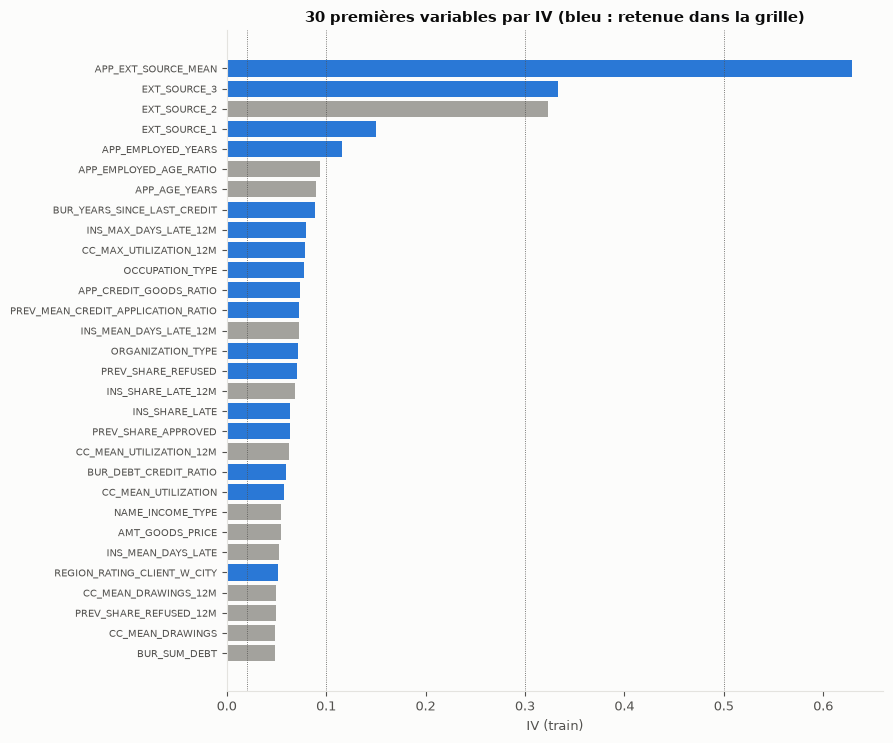

In [3]:
cols = ["variable", "source", "dtype", "iv", "n_bins", "woe_trend", "expected_sense", "observed_sense",
        "iv_gt_0_5", "status", "exclusion_reason"]
display(iv[cols].head(30).style.format({"iv": "{:.4f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 7.5))
top = iv.head(30).iloc[::-1]
ax.barh(top["variable"], top["iv"], color=[BLUE if s == "selected" else GREY for s in top["status"]])
for x in (0.02, 0.1, 0.3, 0.5):
    ax.axvline(x, color=INK2, lw=0.6, ls=":")
ax.set_xlabel("IV (train)")
ax.set_title("30 premières variables par IV (bleu : retenue dans la grille)")
ax.tick_params(axis="y", labelsize=7.5)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_iv_top30.png", dpi=150)
plt.show()

## 2. Distribution des IV

Répartition des 200 candidates par classe d'IV, et par source de données.

classe_iv,"< 0,02","0,02–0,1","0,1–0,3","0,3–0,5","> 0,5",total
source,,,,,,
application,73,50,2,2,1,128
previous_application,9,7,0,0,0,16
credit_card_balance,7,6,0,0,0,13
installments_payments,7,6,0,0,0,13
bureau,6,6,0,0,0,12
bureau_balance via bureau,9,0,0,0,0,9
pos_cash_balance,7,2,0,0,0,9


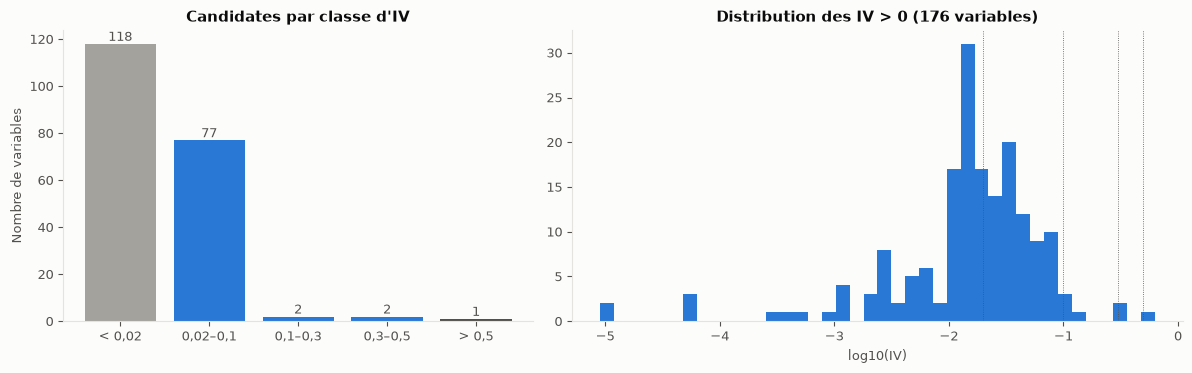

In [4]:
edges = [0, 0.02, 0.1, 0.3, 0.5, np.inf]
labels = ["< 0,02", "0,02–0,1", "0,1–0,3", "0,3–0,5", "> 0,5"]
iv["classe_iv"] = pd.cut(iv["iv"], bins=edges, labels=labels, right=False)
dist = iv["classe_iv"].value_counts().reindex(labels)
by_source = pd.crosstab(iv["source"], iv["classe_iv"]).reindex(columns=labels, fill_value=0)
by_source["total"] = by_source.sum(axis=1)
display(by_source.sort_values("total", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].bar(labels, dist.to_numpy(), color=[GREY] + [BLUE] * 3 + [INK2])
for i, v in enumerate(dist.to_numpy()):
    axes[0].text(i, v, f"{v}", ha="center", va="bottom", color=INK2)
axes[0].set_title("Candidates par classe d'IV")
axes[0].set_ylabel("Nombre de variables")
pos = iv.loc[iv["iv"] > 0, "iv"]
axes[1].hist(np.log10(pos), bins=40, color=BLUE)
for x in (0.02, 0.1, 0.3, 0.5):
    axes[1].axvline(np.log10(x), color=INK2, lw=0.6, ls=":")
axes[1].set_xlabel("log10(IV)")
axes[1].set_title(f"Distribution des IV > 0 ({len(pos)} variables)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_iv_distribution.png", dpi=150)
plt.show()

## 3. WoE des 6 variables d'IV le plus élevé

Barres : WoE par classe (gris : classe « Missing ») ; points : taux de défaut de la classe (axe de droite). Un WoE élevé correspond à un taux de défaut faible.

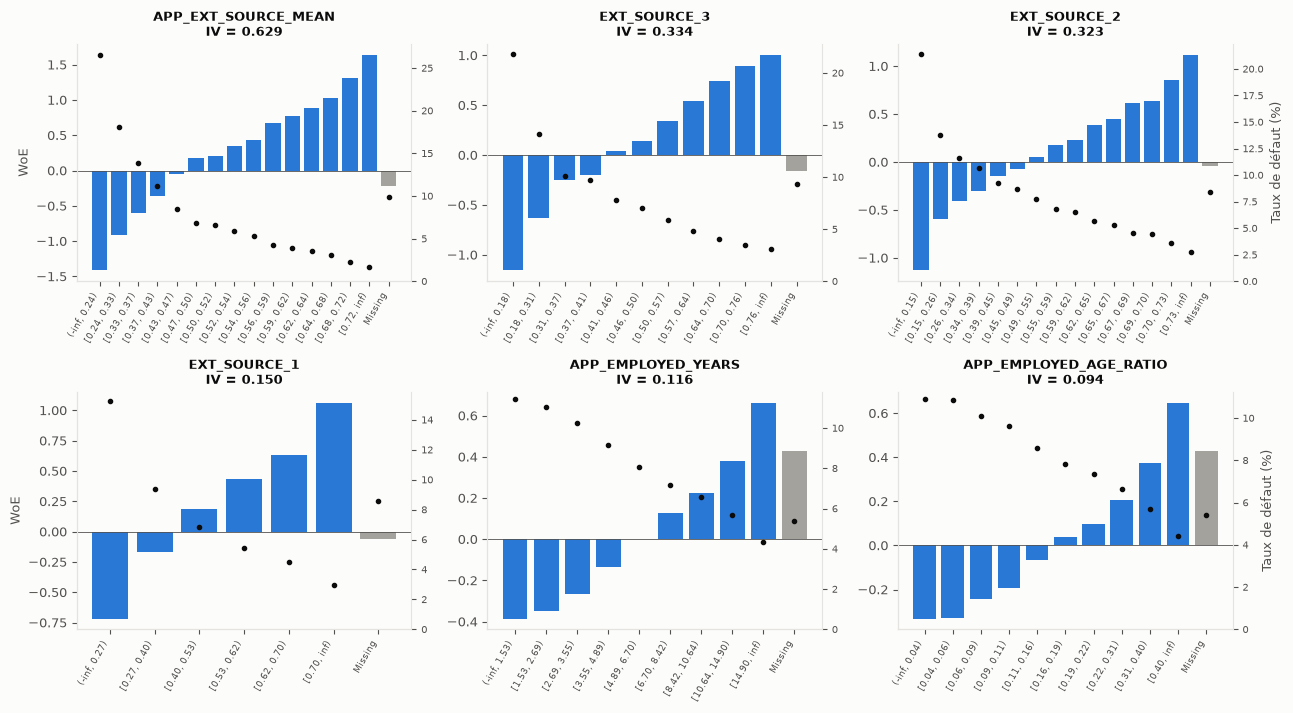

In [5]:
top6 = iv.head(6)["variable"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for ax, var in zip(axes.flat, top6):
    bt = binning_table(bp, var)
    bt = bt[bt["Bin"].ne("Special") & (bt["Count"] > 0)]
    x = np.arange(len(bt))
    ax.bar(x, bt["WoE"].astype(float), color=[GREY if b == "Missing" else BLUE for b in bt["Bin"]])
    ax.axhline(0, color=INK2, lw=0.6)
    ax2 = ax.twinx()
    ax2.plot(x, 100 * bt["Event rate"].astype(float), "o", color=INK, ms=3)
    ax2.set_ylim(bottom=0)
    ax2.spines["right"].set_visible(True)
    ax2.tick_params(labelsize=7)
    if ax in axes[:, -1]:
        ax2.set_ylabel("Taux de défaut (%)")
    ax.set_xticks(x)
    ax.set_xticklabels([b if len(b) <= 14 else b[:13] + "…" for b in bt["Bin"]], rotation=60, ha="right", fontsize=6.5)
    iv_v = float(iv.loc[iv["variable"].eq(var), "iv"].iloc[0])
    ax.set_title(f"{var}\nIV = {iv_v:.3f}", fontsize=9)
axes[0, 0].set_ylabel("WoE")
axes[1, 0].set_ylabel("WoE")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_woe_top6.png", dpi=150)
plt.show()

## 4. Monotonie et sens de la relation

Pour chaque variable, la monotonie est contrôlée sur les classes régulières (hors « Missing ») : WoE croissant = le risque **diminue** quand la variable augmente (sens observé ↓), WoE décroissant = le risque **augmente** (↑).
Le sens observé est confronté au sens attendu a priori dans le catalogue (Phase 2).

In [6]:
mono = pd.crosstab(iv["woe_trend"], iv["dtype"], margins=True, margins_name="total")
display(mono)
n_nonmono = int((~iv["monotone"]).sum())
print(f"Variables à WoE non monotone : {n_nonmono} sur {len(iv)}")

comp = iv[iv["expected_sense"].isin(["↑", "↓"]) & iv["observed_sense"].isin(["↑", "↓"])]
conc = pd.crosstab(comp["expected_sense"], comp["observed_sense"],
                   rownames=["sens attendu"], colnames=["sens observé"])
display(conc)
disc = comp[comp["expected_sense"] != comp["observed_sense"]]
print(f"Sens attendu renseigné et sens observé comparable : {len(comp)} variables ; discordantes : {len(disc)}")
display(disc[["variable", "iv", "expected_sense", "observed_sense", "status", "exclusion_reason"]]
        .style.format({"iv": "{:.4f}"}).hide(axis="index"))

dtype,categorical,numerical,total
woe_trend,,,
catégorielle (ordonnée par taux),13,0,13
constant,1,39,40
croissant,0,87,87
décroissant,0,60,60
total,14,186,200


Variables à WoE non monotone : 0 sur 200


sens observé,↑,↓
sens attendu,,
↑,37,5
↓,5,24


Sens attendu renseigné et sens observé comparable : 71 variables ; discordantes : 10


variable,iv,expected_sense,observed_sense,status,exclusion_reason
PREV_MEAN_CREDIT_APPLICATION_RATIO,0.0726,↓,↑,selected,nan
PREV_MEAN_CREDIT_APPLICATION_RATIO_12M,0.0274,↓,↑,excluded,cap20
AMT_REQ_CREDIT_BUREAU_QRT,0.0162,↑,↓,excluded,iv_low
AMT_REQ_CREDIT_BUREAU_MON,0.0152,↑,↓,excluded,iv_low
INS_NB_INSTALMENTS_12M,0.0107,↓,↑,excluded,iv_low
APP_CREDIT_INCOME_RATIO,0.0043,↑,↓,excluded,iv_low
CC_MAX_DPD,0.0026,↑,↓,excluded,iv_low
CC_SHARE_MONTHS_DPD,0.0026,↑,↓,excluded,iv_low
POS_NB_MONTHS,0.0023,↓,↑,excluded,iv_low
BB_NB_MONTHS_12M,0.0000,↓,↑,excluded,iv_low


## 5. Variables à IV > 0,5 (D18)

Ces variables sont **conservées mais signalées** pour revue : un IV aussi élevé peut traduire une fuite d'information ou une variable dominante.

In [7]:
flag = iv[iv["iv_gt_0_5"]]
display(flag[["variable", "source", "iv", "n_bins", "woe_trend", "status", "exclusion_reason"]]
        .style.format({"iv": "{:.4f}"}).hide(axis="index"))
for var in flag["variable"]:
    display(Markdown(f"**{var}** — formule (catalogue) : {CATALOG[var][1]}"))
    bt = binning_table(bp, var)
    display(bt[["Bin", "Count", "Count (%)", "Event rate", "WoE", "IV"]]
            .style.format({"Count": "{:,}", "Count (%)": "{:.4f}", "Event rate": "{:.4f}", "WoE": "{:.4f}", "IV": "{:.4f}"})
            .hide(axis="index"))

variable,source,iv,n_bins,woe_trend,status,exclusion_reason
APP_EXT_SOURCE_MEAN,application,0.6287,15,croissant,selected,nan


**APP_EXT_SOURCE_MEAN** — formule (catalogue) : Moyenne des EXT_SOURCE_1/2/3 renseignés ; NULL si aucun

Bin,Count,Count (%),Event rate,WoE,IV
"(-inf, 0.24)","11,641",0.0541,0.2656,-1.4155,0.1907
"[0.24, 0.33)","16,151",0.0750,0.1805,-0.9199,0.0928
"[0.33, 0.37)","11,451",0.0532,0.1388,-0.6069,0.0253
"[0.37, 0.43)","20,995",0.0975,0.1114,-0.3556,0.0143
"[0.43, 0.47)","20,885",0.0970,0.0847,-0.0518,0.0003
"[0.47, 0.50)","11,217",0.0521,0.0686,0.1766,0.0015
"[0.50, 0.52)","11,222",0.0521,0.0665,0.2096,0.0021
"[0.52, 0.54)","11,235",0.0522,0.0586,0.3447,0.0054
"[0.54, 0.56)","12,369",0.0575,0.0535,0.4402,0.0093
"[0.56, 0.59)","18,566",0.0863,0.0430,0.6692,0.0293


## 6. Synthèse

In [8]:
n_low = int((iv["iv"] < 0.02).sum())
flag_txt = ", ".join(f"`{r.variable}` (IV {r.iv:.4f}, {'retenue' if r.status == 'selected' else 'exclue'})"
                     for r in flag.itertuples()) or "aucune"
display(Markdown(f"""
**Constats (binning ajusté sur le train, {metrics['n_train']:,} demandes)**
- {len(iv)} candidates binnées ; {n_low} ont un IV < 0,02 et sont exclues (D18) ; {len(iv) - n_low} passent à la sélection.
- Répartition des IV : {", ".join(f"{k} : {v}" for k, v in dist.items())}.
- Variable d'IV maximal : `{iv.iloc[0]['variable']}` (IV {iv.iloc[0]['iv']:.4f}).
- Monotonie : {n_nonmono} variable(s) à WoE non monotone sur {len(iv)}.
- Sens observé discordant avec le sens attendu du catalogue : {len(disc)} variable(s) sur {len(comp)} comparables
  ({", ".join(f"`{v}`" for v in disc["variable"]) or "aucune"}).
- IV > 0,5 (signalées, D18) : {flag_txt}.
"""))


**Constats (binning ajusté sur le train, 215,257 demandes)**
- 200 candidates binnées ; 118 ont un IV < 0,02 et sont exclues (D18) ; 82 passent à la sélection.
- Répartition des IV : < 0,02 : 118, 0,02–0,1 : 77, 0,1–0,3 : 2, 0,3–0,5 : 2, > 0,5 : 1.
- Variable d'IV maximal : `APP_EXT_SOURCE_MEAN` (IV 0.6287).
- Monotonie : 0 variable(s) à WoE non monotone sur 200.
- Sens observé discordant avec le sens attendu du catalogue : 10 variable(s) sur 71 comparables
  (`PREV_MEAN_CREDIT_APPLICATION_RATIO`, `PREV_MEAN_CREDIT_APPLICATION_RATIO_12M`, `AMT_REQ_CREDIT_BUREAU_QRT`, `AMT_REQ_CREDIT_BUREAU_MON`, `INS_NB_INSTALMENTS_12M`, `APP_CREDIT_INCOME_RATIO`, `CC_MAX_DPD`, `CC_SHARE_MONTHS_DPD`, `POS_NB_MONTHS`, `BB_NB_MONTHS_12M`).
- IV > 0,5 (signalées, D18) : `APP_EXT_SOURCE_MEAN` (IV 0.6287, retenue).


In [9]:
con.close()